In [4]:
from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt


PROJECT_DIR = Path(r"C:\BrainScan-v2")
SPLIT_DIR=PROJECT_DIR / "data_split"

# les donne separer
TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

# les paramtre
IMAGE_SIZE = (224,224)
BATCH_SIZE = 32
SEED = 42




In [5]:
# virification des doccier
for directory in [TRAIN_DIR,TEST_DIR,TEST_DIR]:
    if not directory.is_dir():
        raise FileNotFoundError(f"Dossier introuvable : {directory}")

# les nom des class depuis train
class_names =sorted(folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir())

if not class_names:
    raise ValueError("Aucune classe trouvee dans Train.")

print("Classes :", class_names)


Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


In [6]:

# chargement des imgs
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names= class_names,
    image_size= IMAGE_SIZE,
    batch_size= BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=True,
    seed=SEED 
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    class_names=class_names,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=class_names,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)



Found 4708 files belonging to 4 classes.
Found 1009 files belonging to 4 classes.
Found 1009 files belonging to 4 classes.


In [7]:
# normalisation 0 -> 1
def normalize_images(images,labels):
    images=tf.cast(images,tf.float32)/255.0
    return images,labels

train_ds = train_ds.map(normalize_images)
val_ds = val_ds.map(normalize_images)
test_ds = test_ds.map(normalize_images)



dimensions des images : (32, 224, 224, 3)
dimensions des labels : (32,)
pixel minimum : 0.0
pixel maximum : 1.0


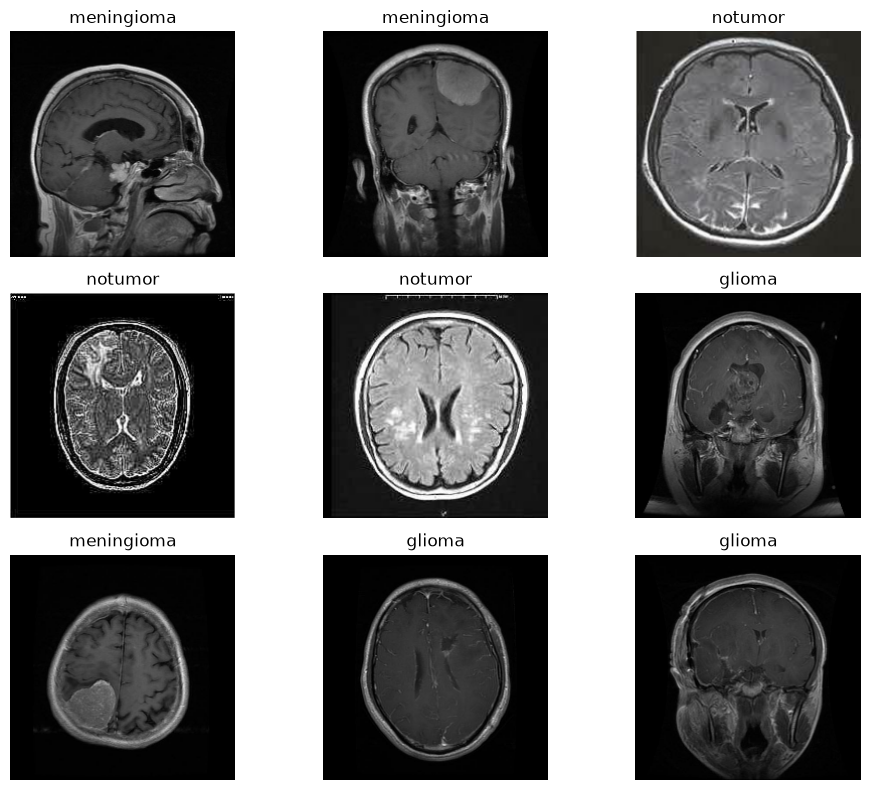

In [8]:
# optimisation du chargement des lots

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# virifier les dimensions et les valeurs 
for images,labels in train_ds.take(1):
    print("dimensions des images :",images.shape)
    print("dimensions des labels :",labels.shape)
    print("pixel minimum :",float(tf.reduce_min(images)))
    print("pixel maximum :",float(tf.reduce_max(images)))


for images,labels in train_ds.take(1):
    plt.figure(figsize=(10,8))

    for i in range(min(9,len(images))):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [9]:
# la creation des couche daugmentation
flip_layer = tf.keras.layers.RandomFlip(#gauche to droite
    mode="horizontal",seed=SEED
)

noise_layer =tf.keras.layers.GaussianNoise(#ajoute de bruit au pixel pendant train
    stddev=0.03,seed=SEED
)

def apply_blur(images):
    # filtre 
    kernel = tf.constant(
        [[1,2,1],
         [2,4,2],
        [1,2,1]
        ],
        dtype=tf.float32
    )/16.0

    kernel = tf.reshape(kernel,[3,3,1,1])
    kernel = tf.tile(kernel,[1,1,3,1])

    return tf.nn.depthwise_conv2d(
        images,kernel,strides=[1,1,1,1],padding="SAME"
    )

def augment_train(images,labels):
    images = flip_layer(images,training=True)
    # ajout un bruit leger
    images = noise_layer(images,training=True)

    # applique le flou avce 20%
    images = tf.cond(
        tf.random.uniform([])<0.20,
        lambda:apply_blur(images),
        lambda:images
    )

    #garder les pixel entre 0 et 1
    images = tf.clip_by_value(images,0.0,1.0)

    return images,labels


# crrer dataset augmente

train_augmented_ds = train_ds.map(
    augment_train,
    num_parallel_calls = tf.data.AUTOTUNE
)

train_augmented_ds = train_augmented_ds.prefetch(
    tf.data.AUTOTUNE
)

print("augmentation appliquee au dataset Train")


augmentation appliquee au dataset Train


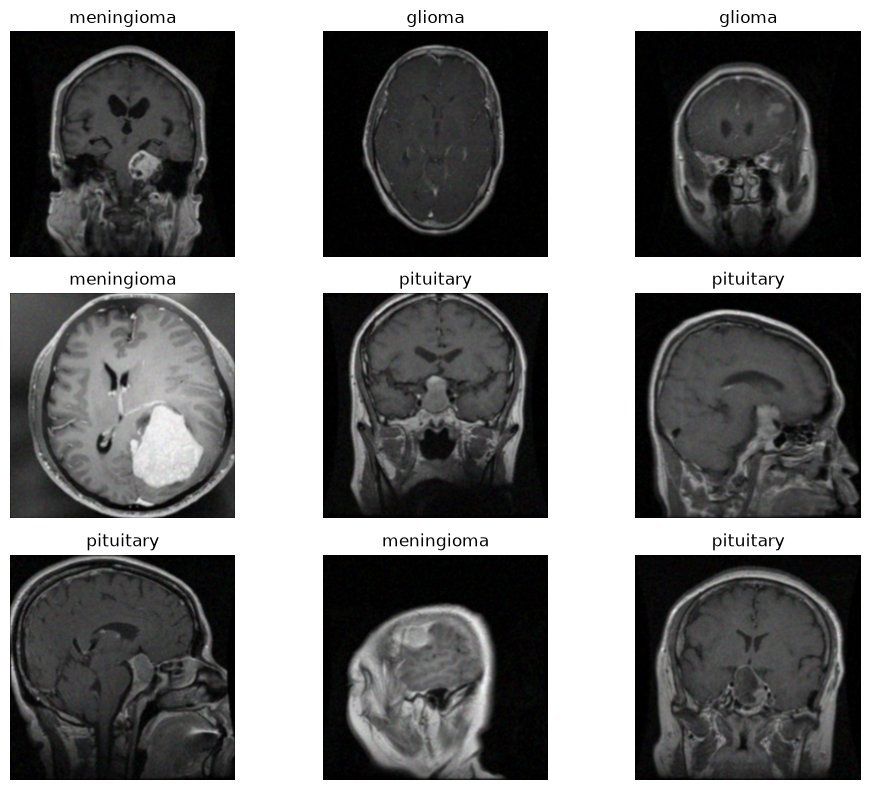

In [10]:
# visualisation des img augmenter

for images,labels in train_augmented_ds.take(1):
    plt.figure(figsize=(10,8))

    for i in range(min(9,len(images))):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [11]:
import tensorflow as tf

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.22.0-rc0
GPU disponible : []


In [13]:
import sys
import tensorflow as tf

print("Python :", sys.version)
print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

Python : 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
TensorFlow : 2.22.0-rc0
GPU : []


In [12]:
print("Classes :", class_names)
print("Train :", train_ds.element_spec)
print("Train augmenté :", train_augmented_ds.element_spec)
print("Validation :", val_ds.element_spec)
print("Test :", test_ds.element_spec)

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Train : (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Train augmenté : (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Validation : (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Test : (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
